# **Stage 1**

**Dataset Preparation & Analysis**

In [3]:
#from google.colab import drive
#drive.mount('/content/drive')

In [4]:
import os
import pandas as pd
from PIL import Image

base_path = "/kaggle/input/datasets/zoya77/breast-cancer-msi-multimodal-image-dataset/MultiModel Breast Cancer MSI Dataset"

modalities = {
    "Ultrasound": "Ultrasound Images_MSI",
    "Histopathology": "Histopathological_MSI",
    "Xray": "Chest_XRay_MSI"
}

data = []

for modality_name, folder_name in modalities.items():

    modality_path = os.path.join(base_path, folder_name)

    for label in os.listdir(modality_path):

        label_path = os.path.join(modality_path, label)

        if not os.path.isdir(label_path):
            continue

        for img_name in os.listdir(label_path):

            img_path = os.path.join(label_path, img_name)

            try:
                img = Image.open(img_path)

                data.append({
                    "Modality": modality_name,
                    "Label": label.lower(),
                    "Width": img.size[0],
                    "Height": img.size[1],
                    "Path": img_path
                })

            except:
                pass

df = pd.DataFrame(data)

print("Dataset Shape:", df.shape)

print("\nClass Distribution:\n")
print(df.groupby(["Modality", "Label"]).size())

print("\nSample Data:\n")
print(df.head())

Dataset Shape: (3052, 5)

Class Distribution:

Modality        Label    
Histopathology  benign       623
                malignant    623
Ultrasound      benign       406
                malignant    400
Xray            malignant    500
                normal       500
dtype: int64

Sample Data:

     Modality   Label  Width  Height  \
0  Ultrasound  benign    227     227   
1  Ultrasound  benign    224     224   
2  Ultrasound  benign    224     224   
3  Ultrasound  benign    224     224   
4  Ultrasound  benign    224     224   

                                                Path  
0  /kaggle/input/datasets/zoya77/breast-cancer-ms...  
1  /kaggle/input/datasets/zoya77/breast-cancer-ms...  
2  /kaggle/input/datasets/zoya77/breast-cancer-ms...  
3  /kaggle/input/datasets/zoya77/breast-cancer-ms...  
4  /kaggle/input/datasets/zoya77/breast-cancer-ms...  


**Proper Multimodal Train/Test_Split**

In [5]:
from sklearn.model_selection import train_test_split

df["Stratify"] = df["Modality"] + "_" + df["Label"]

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["Stratify"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["Stratify"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train Shape:", train_df.shape)
print("Validation Shape:", val_df.shape)
print("Test Shape:", test_df.shape)

print("\nTrain Distribution:\n")
print(train_df.groupby(["Modality", "Label"]).size())

print("\nValidation Distribution:\n")
print(val_df.groupby(["Modality", "Label"]).size())

print("\nTest Distribution:\n")
print(test_df.groupby(["Modality", "Label"]).size())

train_df.to_csv("train.csv", index=False)
val_df.to_csv("val.csv", index=False)
test_df.to_csv("test.csv", index=False)

print("\nCSV files saved successfully")

Train Shape: (2136, 6)
Validation Shape: (458, 6)
Test Shape: (458, 6)

Train Distribution:

Modality        Label    
Histopathology  benign       436
                malignant    436
Ultrasound      benign       284
                malignant    280
Xray            malignant    350
                normal       350
dtype: int64

Validation Distribution:

Modality        Label    
Histopathology  benign       93
                malignant    94
Ultrasound      benign       61
                malignant    60
Xray            malignant    75
                normal       75
dtype: int64

Test Distribution:

Modality        Label    
Histopathology  benign       94
                malignant    93
Ultrasound      benign       61
                malignant    60
Xray            malignant    75
                normal       75
dtype: int64

CSV files saved successfully


# **Stage 2**

**Preprocessing & Augmentation Setup**

In [6]:
# 1. Install TensorFlow
!pip install -q tensorflow

# 2. Imports
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 224
BATCH_SIZE = 32

print(f"TensorFlow Version: {tf.__version__}")
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_test_datagen = ImageDataGenerator(
    rescale=1.0 / 255
)

TensorFlow Version: 2.20.0


**Modality-Specific Data Generators**

In [7]:
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="Path",
    y_col="Label",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True
)

val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="Path",
    y_col="Label",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="Path",
    y_col="Label",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("Train Batch Shape:", next(train_generator)[0].shape)
print("Validation Samples:", val_generator.samples)
print("Test Samples:", test_generator.samples)

Found 2136 validated image filenames belonging to 3 classes.
Found 458 validated image filenames belonging to 3 classes.
Found 458 validated image filenames belonging to 3 classes.
Train Batch Shape: (32, 224, 224, 3)
Validation Samples: 458
Test Samples: 458


# **Stage 3**

**Baseline CNN Model (DenseNet121)**

In [8]:
import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

for layer in base_model.layers:
    layer.trainable = False

x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(512, activation="relu")(x)
x = Dropout(0.5)(x)

x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)

output = Dense(3, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

I0000 00:00:1791717075.039421      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791717075.043287      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,628,355 (29.10 MB)

 Trainable params: 590,851 (2.25 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

**Model Training**

In [9]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3
)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/10
 1/67 ━━━━━━━━━━━━━━━━━━━━ 35:17 32s/step - accuracy: 0.3125 - loss: 1.4194

I0000 00:00:1791717113.044530     134 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


67/67 ━━━━━━━━━━━━━━━━━━━━ 104s 1s/step - accuracy: 0.4780 - loss: 1.0391 - val_accuracy: 0.5873 - val_loss: 0.7086 - learning_rate: 1.0000e-04
Epoch 2/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 33s 496ms/step - accuracy: 0.5669 - loss: 0.8020 - val_accuracy: 0.6703 - val_loss: 0.6477 - learning_rate: 1.0000e-04
Epoch 3/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 33s 494ms/step - accuracy: 0.5815 - loss: 0.7580 - val_accuracy: 0.6397 - val_loss: 0.6226 - learning_rate: 1.0000e-04
Epoch 4/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 33s 485ms/step - accuracy: 0.5875 - loss: 0.7362 - val_accuracy: 0.6769 - val_loss: 0.6046 - learning_rate: 1.0000e-04
Epoch 5/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 33s 488ms/step - accuracy: 0.6119 - loss: 0.7021 - val_accuracy: 0.6856 - val_loss: 0.5884 - learning_rate: 1.0000e-04
Epoch 6/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 33s 488ms/step - accuracy: 0.6292 - loss: 0.6843 - val_accuracy: 0.7096 - val_loss: 0.5766 - learning_rate: 1.0000e-04
Epoch 7/10
67/67 ━━━━━━━━━━━━━━━━━━━━ 33s 488ms/step - accuracy: 0.6227

**Model Evaluation**

In [10]:
test_loss, test_accuracy = model.evaluate(test_generator)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 138ms/step - accuracy: 0.6856 - loss: 0.5519
Test Loss: 0.5519
Test Accuracy: 0.6856


**Prediction & Classification Report**

In [11]:
import numpy as np
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

predictions = model.predict(test_generator)

y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

class_labels = list(test_generator.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_labels))

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:\n")
print(cm)

15/15 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step 
              precision    recall  f1-score   support

      benign       0.75      0.81      0.78       155
   malignant       0.71      0.63      0.67       228
      normal       0.52      0.60      0.56        75

    accuracy                           0.69       458
   macro avg       0.66      0.68      0.67       458
weighted avg       0.69      0.69      0.69       458


Confusion Matrix:

[[125  30   0]
 [ 42 144  42]
 [  0  30  45]]


**Evaluation Plots**

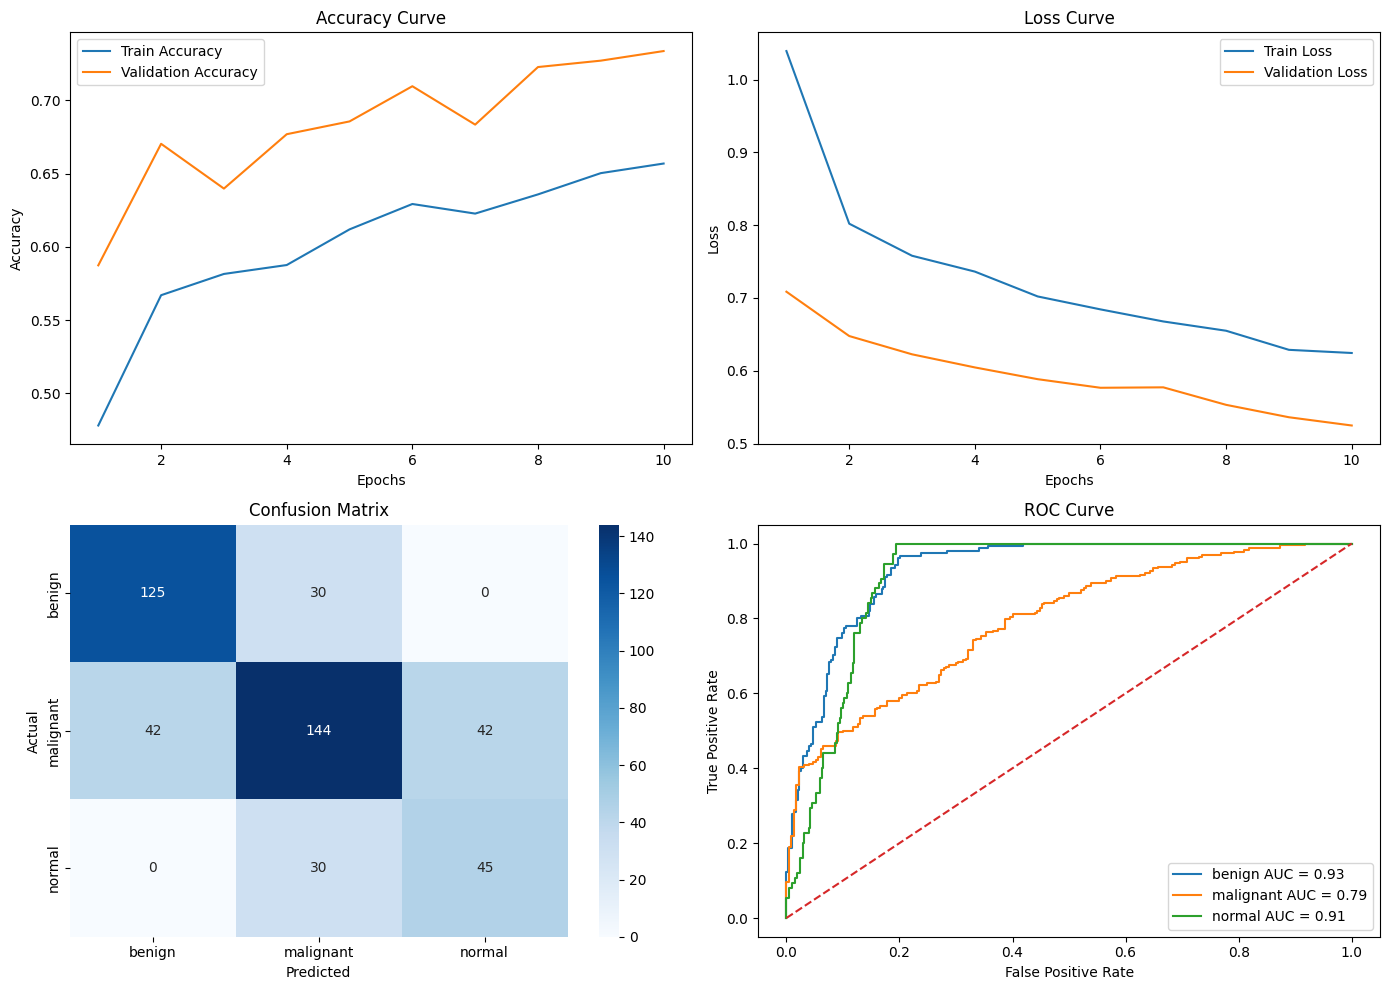

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
from sklearn.preprocessing import label_binarize

train_acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(train_acc) + 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0,0].plot(epochs, train_acc, label="Train Accuracy")
axes[0,0].plot(epochs, val_acc, label="Validation Accuracy")
axes[0,0].set_title("Accuracy Curve")
axes[0,0].set_xlabel("Epochs")
axes[0,0].set_ylabel("Accuracy")
axes[0,0].legend()

axes[0,1].plot(epochs, train_loss, label="Train Loss")
axes[0,1].plot(epochs, val_loss, label="Validation Loss")
axes[0,1].set_title("Loss Curve")
axes[0,1].set_xlabel("Epochs")
axes[0,1].set_ylabel("Loss")
axes[0,1].legend()

cm = confusion_matrix(y_true, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels,
    ax=axes[1,0]
)

axes[1,0].set_title("Confusion Matrix")
axes[1,0].set_xlabel("Predicted")
axes[1,0].set_ylabel("Actual")

y_true_bin = label_binarize(y_true, classes=[0,1,2])

for i in range(3):

    fpr, tpr, _ = roc_curve(
        y_true_bin[:, i],
        predictions[:, i]
    )

    roc_auc = auc(fpr, tpr)

    axes[1,1].plot(
        fpr,
        tpr,
        label=f"{class_labels[i]} AUC = {roc_auc:.2f}"
    )

axes[1,1].plot([0,1], [0,1], linestyle="--")

axes[1,1].set_title("ROC Curve")
axes[1,1].set_xlabel("False Positive Rate")
axes[1,1].set_ylabel("True Positive Rate")
axes[1,1].legend()

plt.tight_layout()
plt.show()

# **Stage 4**

In [13]:
import tensorflow as tf
import tensorflow_hub as hub

IMG_SIZE = 224

# Histopathology Expert
histopathology_model = tf.keras.applications.ConvNeXtTiny(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Ultrasound Expert
swin_model = hub.KerasLayer(
    "https://tfhub.dev/sayakpaul/swin_tiny_patch4_window7_224/1",
    trainable=False
)

# Xray Expert
vit_model = hub.KerasLayer(
    "https://tfhub.dev/sayakpaul/vit_b16_fe/1",
    trainable=False
)

print("Histopathology Expert : ConvNeXtTiny")
print("Ultrasound Expert     : Swin Transformer")
print("Xray Expert           : Vision Transformer")

/usr/local/lib/python3.12/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Histopathology Expert : ConvNeXtTiny
Ultrasound Expert     : Swin Transformer
Xray Expert           : Vision Transformer


**Feature Extraction Validation**

In [14]:
sample_images, sample_labels = next(train_generator)

# ConvNeXt Features
histopathology_features = histopathology_model.predict(sample_images)

# Swin Transformer Features
ultrasound_features = swin_model(sample_images)

# Vision Transformer Features
xray_features = vit_model(sample_images)

print("Input Batch Shape:")
print(sample_images.shape)

print("\nConvNeXt Feature Shape:")
print(histopathology_features.shape)

print("\nSwin Transformer Feature Shape:")
print(ultrasound_features.shape)

print("\nVision Transformer Feature Shape:")
print(xray_features.shape)

2026-10-11 11:19:04.489585: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:19:04.625316: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
Input Batch Shape:
(32, 224, 224, 3)

ConvNeXt Feature Shape:
(32, 7, 7, 768)

Swin Transformer Feature Shape:
(32, 1000)

Vision Transformer Feature Shape:
(32, 768)


# **Stage 5**

**Attention Modules with Advanced Backbones**

**Enhanced Expert Models**

In [15]:
import tensorflow as tf

from tensorflow.keras.layers import Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.layers import GlobalMaxPooling2D
from tensorflow.keras.layers import Reshape
from tensorflow.keras.layers import Multiply
from tensorflow.keras.layers import Concatenate
from tensorflow.keras.layers import Conv2D

from tensorflow.keras.models import Model


IMG_SIZE = 224


def se_block(inputs, ratio=16):

    filters = inputs.shape[-1]

    se = GlobalAveragePooling2D()(inputs)

    se = Reshape((1, 1, filters))(se)

    se = Dense(filters // ratio, activation="relu")(se)

    se = Dense(filters, activation="sigmoid")(se)

    return Multiply()([inputs, se])


def cbam_block(inputs):

    filters = inputs.shape[-1]

    avg_pool = GlobalAveragePooling2D()(inputs)

    max_pool = GlobalMaxPooling2D()(inputs)

    avg_pool = Dense(filters // 8, activation="relu")(avg_pool)
    avg_pool = Dense(filters)(avg_pool)

    max_pool = Dense(filters // 8, activation="relu")(max_pool)
    max_pool = Dense(filters)(max_pool)

    attention = tf.keras.layers.Add()([avg_pool, max_pool])

    attention = tf.keras.layers.Activation("sigmoid")(attention)

    attention = Reshape((1, 1, filters))(attention)

    refined = Multiply()([inputs, attention])

    return refined


# Histopathology Expert
histopathology_input = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

histopathology_base = tf.keras.applications.MobileNetV3Large(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

histopathology_base.trainable = False

histopathology_features = histopathology_base(histopathology_input)

histopathology_features = se_block(histopathology_features)

histopathology_features = GlobalAveragePooling2D()(histopathology_features)

histopathology_features = Dense(256, activation="relu")(histopathology_features)

histopathology_features = BatchNormalization()(histopathology_features)

histopathology_features = Dropout(0.3)(histopathology_features)

histopathology_output = Dense(
    1,
    activation="sigmoid"
)(histopathology_features)

histopathology_expert = Model(
    inputs=histopathology_input,
    outputs=histopathology_output
)


# Ultrasound Expert
ultrasound_input = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

ultrasound_base = tf.keras.applications.EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

ultrasound_base.trainable = False

ultrasound_features = ultrasound_base(ultrasound_input)

ultrasound_features = cbam_block(ultrasound_features)

ultrasound_features = GlobalAveragePooling2D()(ultrasound_features)

ultrasound_features = Dense(256, activation="relu")(ultrasound_features)

ultrasound_features = BatchNormalization()(ultrasound_features)

ultrasound_features = Dropout(0.3)(ultrasound_features)

ultrasound_output = Dense(
    1,
    activation="sigmoid"
)(ultrasound_features)

ultrasound_expert = Model(
    inputs=ultrasound_input,
    outputs=ultrasound_output
)


# Xray Expert
xray_input = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

xray_base = tf.keras.applications.DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

xray_base.trainable = False

xray_features = xray_base(xray_input)

xray_features = se_block(xray_features)

xray_features = GlobalAveragePooling2D()(xray_features)

xray_features = Dense(256, activation="relu")(xray_features)

xray_features = BatchNormalization()(xray_features)

xray_features = Dropout(0.3)(xray_features)

xray_output = Dense(
    1,
    activation="sigmoid"
)(xray_features)

xray_expert = Model(
    inputs=xray_input,
    outputs=xray_output
)

print("Histopathology Expert Ready")
print("Ultrasound Expert Ready")
print("Xray Expert Ready")

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Histopathology Expert Ready
Ultrasound Expert Ready
Xray Expert Ready


In [16]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 224
BATCH_SIZE = 4

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    rescale=1./255
)


# Histopathology
histopathology_train = train_df[
    train_df["Modality"] == "Histopathology"
]

histopathology_val = val_df[
    val_df["Modality"] == "Histopathology"
]


# Ultrasound
ultrasound_train = train_df[
    train_df["Modality"] == "Ultrasound"
]

ultrasound_val = val_df[
    val_df["Modality"] == "Ultrasound"
]


# Xray
xray_train = train_df[
    train_df["Modality"] == "Xray"
]

xray_val = val_df[
    val_df["Modality"] == "Xray"
]


histopathology_train_generator = train_datagen.flow_from_dataframe(
    histopathology_train,
    x_col="Path",
    y_col="Label",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="raw"
)

histopathology_val_generator = val_datagen.flow_from_dataframe(
    histopathology_val,
    x_col="Path",
    y_col="Label",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="raw"
)


ultrasound_train_generator = train_datagen.flow_from_dataframe(
    ultrasound_train,
    x_col="Path",
    y_col="Label",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="raw"
)

ultrasound_val_generator = val_datagen.flow_from_dataframe(
    ultrasound_val,
    x_col="Path",
    y_col="Label",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="raw"
)


xray_train_generator = train_datagen.flow_from_dataframe(
    xray_train,
    x_col="Path",
    y_col="Label",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="raw"
)

xray_val_generator = val_datagen.flow_from_dataframe(
    xray_val,
    x_col="Path",
    y_col="Label",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="raw"
)

print("Generators Ready")

Found 872 validated image filenames.
Found 187 validated image filenames.
Found 564 validated image filenames.
Found 121 validated image filenames.
Found 700 validated image filenames.
Found 150 validated image filenames.
Generators Ready


**Model Validation**

In [17]:
sample_images, sample_labels = next(histopathology_train_generator)

histopathology_predictions = histopathology_expert.predict(sample_images)

sample_images, sample_labels = next(ultrasound_train_generator)

ultrasound_predictions = ultrasound_expert.predict(sample_images)

sample_images, sample_labels = next(xray_train_generator)

xray_predictions = xray_expert.predict(sample_images)

print("Histopathology Output Shape:")
print(histopathology_predictions.shape)

print("\nUltrasound Output Shape:")
print(ultrasound_predictions.shape)

print("\nXray Output Shape:")
print(xray_predictions.shape)

print("\nSample Histopathology Prediction:")
print(histopathology_predictions[0])

print("\nSample Ultrasound Prediction:")
print(ultrasound_predictions[0])

print("\nSample Xray Prediction:")
print(xray_predictions[0])

2026-10-11 11:19:32.352756: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng39{k25=2} for conv (f32[4,480,1,1]{3,2,1,0}, u8[0]{0}) custom-call(f32[4,120,1,1]{3,2,1,0}, f32[480,120,1,1]{3,2,1,0}, f32[480]{0}, f32[4,480,1,1]{3,2,1,0}), window={size=1x1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":1,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-10-11 11:19:33.352256: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.999628526s
Trying algorithm eng39{k25=2} for conv (f32[4,480,1,1]{3,2,1,0}, u8[0]{0}) custom-call(f32[4,120,1,1]{3,2,1,0}, f32[480,120,1,1]{3,2,1,0}, f32[480]{0}, f32[4,480,1,1]{3,2,1,0}), window={size=1x1}, dim_labels=bf01_oi01->bf01, custom_call_targe

1/1 ━━━━━━━━━━━━━━━━━━━━ 17s 17s/step


2026-10-11 11:19:45.510667: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:19:45.643597: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:19:45.928668: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:19:46.070449: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:19:46.875804: E external/local_xla/xla/stream_

1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 15s 15s/step
Histopathology Output Shape:
(4, 1)

Ultrasound Output Shape:
(4, 1)

Xray Output Shape:
(4, 1)

Sample Histopathology Prediction:
[0.57276434]

Sample Ultrasound Prediction:
[0.46785843]

Sample Xray Prediction:
[0.7057897]


# **Stage 6**

**1 — Compile & Configure Training**

In [19]:
import tensorflow as tf
import gc

gc.collect()
tf.keras.backend.clear_session()

# Option A: Define histopathology_optimizer directly
histopathology_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4
)

histopathology_expert.compile(
    optimizer=histopathology_optimizer,
    loss=tf.keras.losses.BinaryFocalCrossentropy(
        gamma=2
    ),
    metrics=['accuracy']
)

**2 — Train Expert Models**

**1 — Histopathology Training**

In [20]:
label_mapping = {
    "benign": 0,
    "malignant": 1,
    "normal": 0,
    "Normal": 0,
    "Malignant": 1
}

train_df["Label"] = train_df["Label"].map(label_mapping).fillna(train_df["Label"])
val_df["Label"] = val_df["Label"].map(label_mapping).fillna(val_df["Label"])
test_df["Label"] = test_df["Label"].map(label_mapping).fillna(test_df["Label"])

train_df["Label"] = pd.to_numeric(train_df["Label"])
val_df["Label"] = pd.to_numeric(val_df["Label"])
test_df["Label"] = pd.to_numeric(test_df["Label"])

train_df["Label"] = train_df["Label"].astype("float32")
val_df["Label"] = val_df["Label"].astype("float32")
test_df["Label"] = test_df["Label"].astype("float32")

print(train_df["Label"].unique())
print(train_df["Label"].dtype)

[0. 1.]
float32


In [21]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras import Input


IMG_SIZE = 224
BATCH_SIZE = 8
EPOCHS = 15


# =========================
# LABEL CLEANING
# =========================

label_mapping = {
    "benign": 0,
    "malignant": 1,
    "normal": 0
}

histopathology_train = histopathology_train.copy()
histopathology_val = histopathology_val.copy()

histopathology_train["Label"] = (
    histopathology_train["Label"]
    .astype(str)
    .str.lower()
    .map(label_mapping)
    .astype(np.float32)
)

histopathology_val["Label"] = (
    histopathology_val["Label"]
    .astype(str)
    .str.lower()
    .map(label_mapping)
    .astype(np.float32)
)


# =========================
# TF DATASET
# =========================

train_paths = histopathology_train["Path"].values
train_labels = histopathology_train["Label"].values

val_paths = histopathology_val["Path"].values
val_labels = histopathology_val["Label"].values


def preprocess_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label


train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_dataset = (
    train_dataset
    .shuffle(1000)
    .map(preprocess_image)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


val_dataset = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_dataset = (
    val_dataset
    .map(preprocess_image)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


# =========================
# CUSTOM CNN
# =========================

inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = Conv2D(32, (3,3), activation="relu")(inputs)
x = MaxPooling2D()(x)

x = Conv2D(64, (3,3), activation="relu")(x)
x = MaxPooling2D()(x)

x = Conv2D(128, (3,3), activation="relu")(x)
x = MaxPooling2D()(x)

x = GlobalAveragePooling2D()(x)

x = Dense(128, activation="relu")(x)

x = Dropout(0.3)(x)

outputs = Dense(1, activation="sigmoid")(x)

histopathology_expert = Model(inputs, outputs)

In [22]:
histopathology_expert.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)


early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


print("\nTraining Histopathology Expert\n")


histopathology_history = histopathology_expert.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[early_stop]
)


Training Histopathology Expert

Epoch 1/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - accuracy: 0.5310 - auc: 0.5602 - loss: 0.6886 - precision: 0.5434 - recall: 0.3876 - val_accuracy: 0.6578 - val_auc: 0.7696 - val_loss: 0.6723 - val_precision: 0.9688 - val_recall: 0.3298
Epoch 2/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.6227 - auc: 0.6644 - loss: 0.6614 - precision: 0.6247 - recall: 0.6147 - val_accuracy: 0.6738 - val_auc: 0.7839 - val_loss: 0.6183 - val_precision: 0.6364 - val_recall: 0.8191
Epoch 3/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.6089 - auc: 0.6751 - loss: 0.6405 - precision: 0.6112 - recall: 0.5986 - val_accuracy: 0.6791 - val_auc: 0.7898 - val_loss: 0.5874 - val_precision: 0.7742 - val_recall: 0.5106
Epoch 4/15
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.6365 - auc: 0.7005 - loss: 0.6246 - precision: 0.6434 - recall: 0.6124 - val_accuracy: 0.6631 - val_auc: 0.7931 - val_loss: 0.6017 - val_precision: 0.8780 - val_recall: 0

**Ultrasound Expert — Custom CNN Stable Version**

In [23]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras import Input


IMG_SIZE = 224
BATCH_SIZE = 8
EPOCHS = 15


# =========================
# LABEL CLEANING
# =========================

label_mapping = {
    "benign": 0,
    "malignant": 1,
    "normal": 0
}

ultrasound_train = ultrasound_train.copy()
ultrasound_val = ultrasound_val.copy()

ultrasound_train["Label"] = (
    ultrasound_train["Label"]
    .astype(str)
    .str.lower()
    .map(label_mapping)
    .astype(np.float32)
)

ultrasound_val["Label"] = (
    ultrasound_val["Label"]
    .astype(str)
    .str.lower()
    .map(label_mapping)
    .astype(np.float32)
)


# =========================
# TF DATASET
# =========================

train_paths = ultrasound_train["Path"].values
train_labels = ultrasound_train["Label"].values

val_paths = ultrasound_val["Path"].values
val_labels = ultrasound_val["Label"].values


def preprocess_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label


train_dataset_ultrasound = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_dataset_ultrasound = (
    train_dataset_ultrasound
    .shuffle(1000)
    .map(preprocess_image)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


val_dataset_ultrasound = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_dataset_ultrasound = (
    val_dataset_ultrasound
    .map(preprocess_image)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


# =========================
# CUSTOM CNN
# =========================

inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = Conv2D(32, (3,3), activation="relu")(inputs)
x = BatchNormalization()(x)
x = MaxPooling2D()(x)

x = Conv2D(64, (3,3), activation="relu")(x)
x = BatchNormalization()(x)
x = MaxPooling2D()(x)

x = Conv2D(128, (3,3), activation="relu")(x)
x = BatchNormalization()(x)
x = MaxPooling2D()(x)

x = GlobalAveragePooling2D()(x)

x = Dense(128, activation="relu")(x)

x = Dropout(0.4)(x)

outputs = Dense(1, activation="sigmoid")(x)

ultrasound_expert = Model(inputs, outputs)


# =========================
# COMPILE
# =========================

ultrasound_expert.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)


early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


# =========================
# TRAINING
# =========================

print("\nTraining Ultrasound Expert\n")

ultrasound_history = ultrasound_expert.fit(
    train_dataset_ultrasound,
    validation_data=val_dataset_ultrasound,
    epochs=EPOCHS,
    callbacks=[early_stop]
)


Training Ultrasound Expert

Epoch 1/15
70/71 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5825 - auc: 0.6071 - loss: 0.7008 - precision: 0.5683 - recall: 0.6798

2026-10-11 11:42:30.617126: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-11 11:42:30.759915: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


71/71 ━━━━━━━━━━━━━━━━━━━━ 16s 122ms/step - accuracy: 0.6365 - auc: 0.6761 - loss: 0.6558 - precision: 0.6280 - recall: 0.6571 - val_accuracy: 0.5041 - val_auc: 0.6122 - val_loss: 0.6906 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.7181 - auc: 0.7748 - loss: 0.5832 - precision: 0.7232 - recall: 0.7000 - val_accuracy: 0.4959 - val_auc: 0.6648 - val_loss: 0.6991 - val_precision: 0.4958 - val_recall: 0.9833
Epoch 3/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.7500 - auc: 0.8218 - loss: 0.5271 - precision: 0.7584 - recall: 0.7286 - val_accuracy: 0.4959 - val_auc: 0.6128 - val_loss: 0.7401 - val_precision: 0.4959 - val_recall: 1.0000
Epoch 4/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.7482 - auc: 0.8208 - loss: 0.5245 - precision: 0.7614 - recall: 0.7179 - val_accuracy: 0.4876 - val_auc: 0.6292 - val_loss: 0.7661 - val_precision: 0.4917 - val_recall: 0.9833
Epoch 5/15
71/71 ━━━━━━━━━━━━━━━━━━━━

**Xray Expert — Custom CNN Stable Version**

In [24]:
import tensorflow as tf
import numpy as np

from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras import Input


IMG_SIZE = 224
BATCH_SIZE = 8
EPOCHS = 15


# =========================
# LABEL CLEANING
# =========================

label_mapping = {
    "normal": 0,
    "benign": 0,
    "malignant": 1
}

xray_train = xray_train.copy()
xray_val = xray_val.copy()

xray_train["Label"] = (
    xray_train["Label"]
    .astype(str)
    .str.lower()
    .map(label_mapping)
    .astype(np.float32)
)

xray_val["Label"] = (
    xray_val["Label"]
    .astype(str)
    .str.lower()
    .map(label_mapping)
    .astype(np.float32)
)


# =========================
# TF DATASET
# =========================

train_paths = xray_train["Path"].values
train_labels = xray_train["Label"].values

val_paths = xray_val["Path"].values
val_labels = xray_val["Label"].values


def preprocess_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(image, tf.float32) / 255.0

    return image, label


train_dataset_xray = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_dataset_xray = (
    train_dataset_xray
    .shuffle(1000)
    .map(preprocess_image)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


val_dataset_xray = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_dataset_xray = (
    val_dataset_xray
    .map(preprocess_image)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


# =========================
# CUSTOM CNN
# =========================

inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = Conv2D(32, (3,3), activation="relu")(inputs)
x = BatchNormalization()(x)
x = MaxPooling2D()(x)

x = Conv2D(64, (3,3), activation="relu")(x)
x = BatchNormalization()(x)
x = MaxPooling2D()(x)

x = Conv2D(128, (3,3), activation="relu")(x)
x = BatchNormalization()(x)
x = MaxPooling2D()(x)

x = GlobalAveragePooling2D()(x)

x = Dense(128, activation="relu")(x)

x = Dropout(0.4)(x)

outputs = Dense(1, activation="sigmoid")(x)

xray_expert = Model(inputs, outputs)


# =========================
# COMPILE
# =========================

xray_expert.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)


early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


# =========================
# TRAINING
# =========================

print("\nTraining Xray Expert\n")

xray_history = xray_expert.fit(
    train_dataset_xray,
    validation_data=val_dataset_xray,
    epochs=EPOCHS,
    callbacks=[early_stop]
)


Training Xray Expert

Epoch 1/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 92ms/step - accuracy: 0.5186 - auc: 0.5321 - loss: 0.7123 - precision: 0.5173 - recall: 0.5543 - val_accuracy: 0.5000 - val_auc: 0.5529 - val_loss: 0.6958 - val_precision: 0.5000 - val_recall: 1.0000
Epoch 2/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.5329 - auc: 0.5595 - loss: 0.7032 - precision: 0.5347 - recall: 0.5057 - val_accuracy: 0.5000 - val_auc: 0.4074 - val_loss: 0.7008 - val_precision: 0.5000 - val_recall: 1.0000
Epoch 3/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.5171 - auc: 0.5244 - loss: 0.7072 - precision: 0.5168 - recall: 0.5286 - val_accuracy: 0.5000 - val_auc: 0.4746 - val_loss: 0.7066 - val_precision: 0.5000 - val_recall: 1.0000
Epoch 4/15
88/88 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.5529 - auc: 0.5810 - loss: 0.6885 - precision: 0.5521 - recall: 0.5600 - val_accuracy: 0.5000 - val_auc: 0.5309 - val_loss: 0.7090 - val_precision: 0.5000 - val_recall: 1.0000
Epoch 5/15
8

 # **Stage 7 — Evaluation & Visualization**

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step


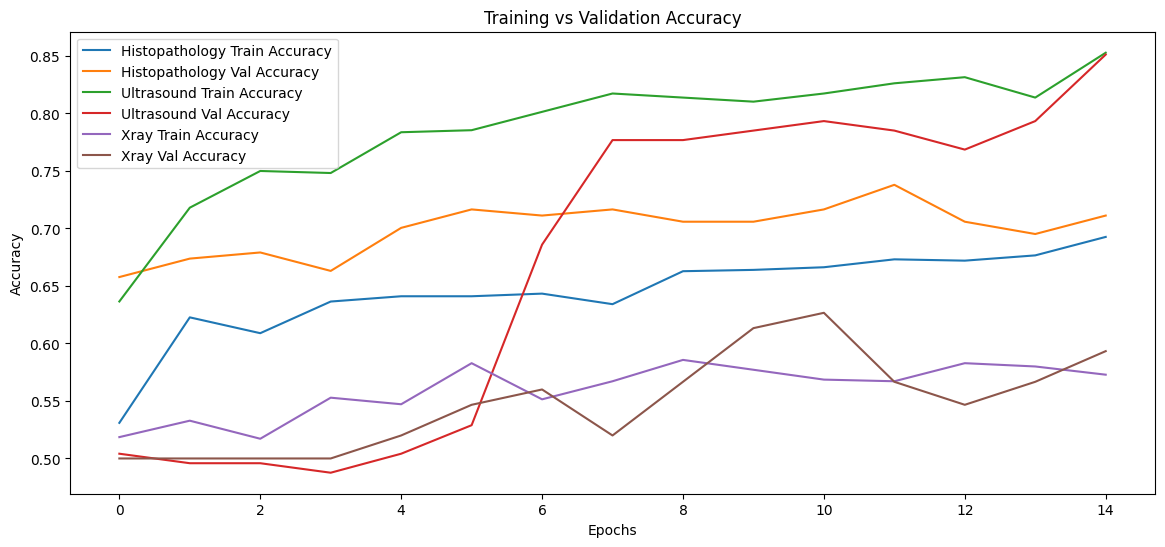

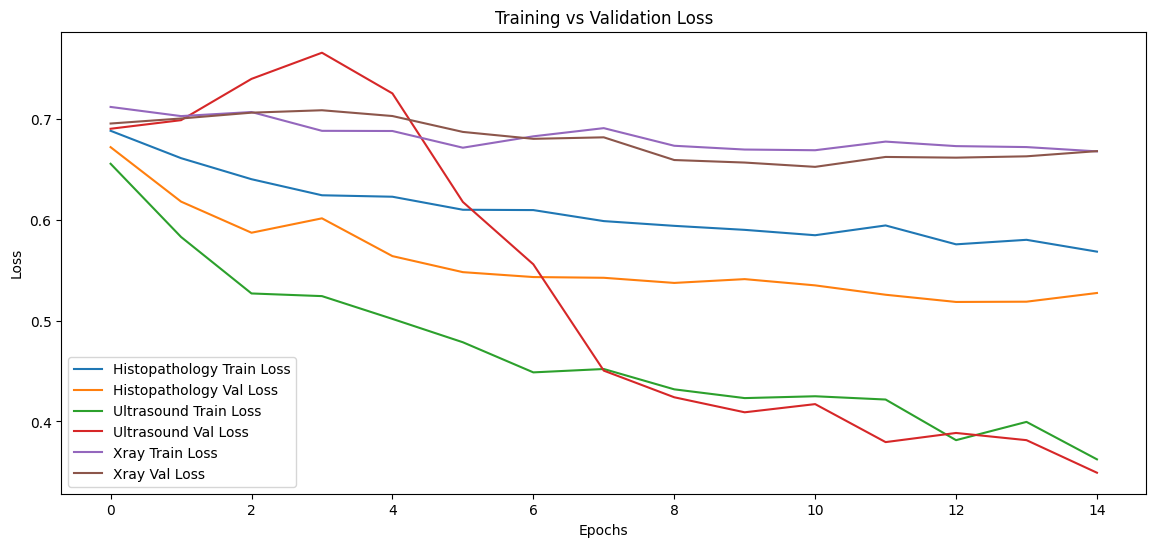

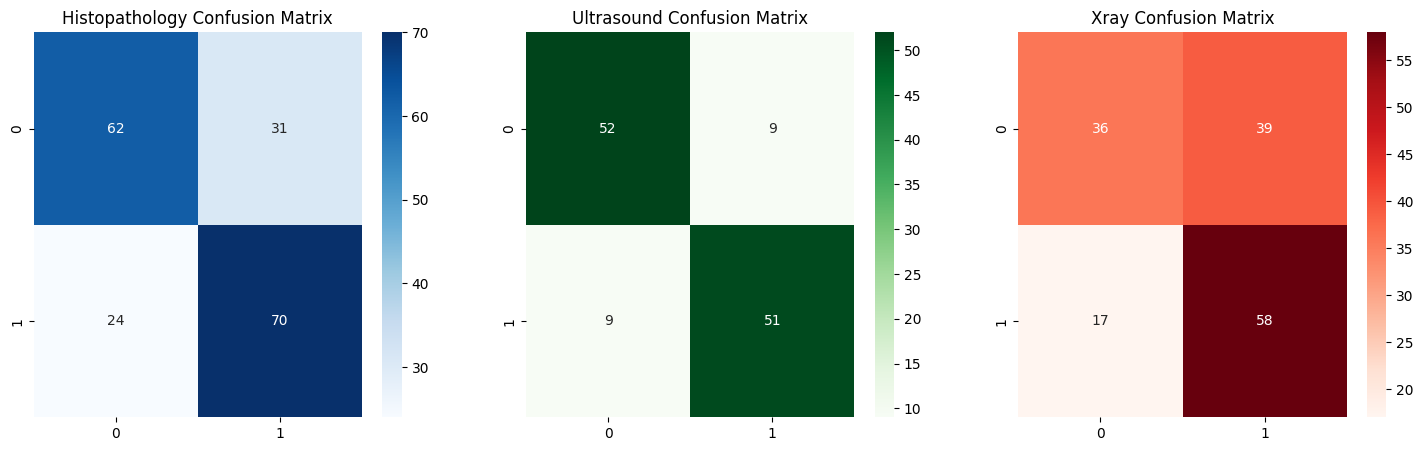

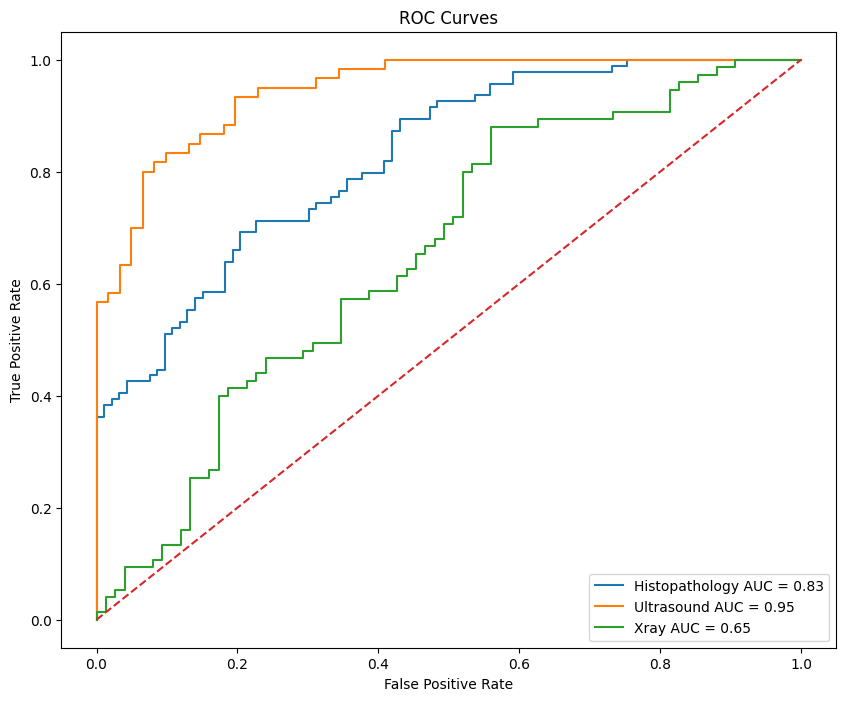


HISTOPATHOLOGY REPORT

              precision    recall  f1-score   support

         0.0       0.72      0.67      0.69        93
         1.0       0.69      0.74      0.72        94

    accuracy                           0.71       187
   macro avg       0.71      0.71      0.71       187
weighted avg       0.71      0.71      0.71       187


ULTRASOUND REPORT

              precision    recall  f1-score   support

         0.0       0.85      0.85      0.85        61
         1.0       0.85      0.85      0.85        60

    accuracy                           0.85       121
   macro avg       0.85      0.85      0.85       121
weighted avg       0.85      0.85      0.85       121


XRAY REPORT

              precision    recall  f1-score   support

         0.0       0.68      0.48      0.56        75
         1.0       0.60      0.77      0.67        75

    accuracy                           0.63       150
   macro avg       0.64      0.63      0.62       150
weighted avg    

In [25]:
# =========================================================
# STAGE 7 — FINAL EVALUATION & VISUALIZATION
# =========================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)


# =========================================================
# HISTOPATHOLOGY PREDICTIONS
# =========================================================

histopathology_predictions = (
    histopathology_expert.predict(val_dataset)
)

histopathology_pred_labels = (
    histopathology_predictions > 0.5
).astype(int)

histopathology_true = np.concatenate([
    y for x, y in val_dataset
])


# =========================================================
# ULTRASOUND PREDICTIONS
# =========================================================

ultrasound_predictions = (
    ultrasound_expert.predict(
        val_dataset_ultrasound
    )
)

ultrasound_pred_labels = (
    ultrasound_predictions > 0.5
).astype(int)

ultrasound_true = np.concatenate([
    y for x, y in val_dataset_ultrasound
])


# =========================================================
# XRAY PREDICTIONS
# =========================================================

xray_predictions = (
    xray_expert.predict(
        val_dataset_xray
    )
)

xray_pred_labels = (
    xray_predictions > 0.5
).astype(int)

xray_true = np.concatenate([
    y for x, y in val_dataset_xray
])


# =========================================================
# ACCURACY PLOTS
# =========================================================

plt.figure(figsize=(14, 6))


# Histopathology
plt.plot(
    histopathology_history.history["accuracy"],
    label="Histopathology Train Accuracy"
)

plt.plot(
    histopathology_history.history["val_accuracy"],
    label="Histopathology Val Accuracy"
)


# Ultrasound
plt.plot(
    ultrasound_history.history["accuracy"],
    label="Ultrasound Train Accuracy"
)

plt.plot(
    ultrasound_history.history["val_accuracy"],
    label="Ultrasound Val Accuracy"
)


# Xray
plt.plot(
    xray_history.history["accuracy"],
    label="Xray Train Accuracy"
)

plt.plot(
    xray_history.history["val_accuracy"],
    label="Xray Val Accuracy"
)

plt.title("Training vs Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()

plt.show()


# =========================================================
# LOSS PLOTS
# =========================================================

plt.figure(figsize=(14, 6))


# Histopathology
plt.plot(
    histopathology_history.history["loss"],
    label="Histopathology Train Loss"
)

plt.plot(
    histopathology_history.history["val_loss"],
    label="Histopathology Val Loss"
)


# Ultrasound
plt.plot(
    ultrasound_history.history["loss"],
    label="Ultrasound Train Loss"
)

plt.plot(
    ultrasound_history.history["val_loss"],
    label="Ultrasound Val Loss"
)


# Xray
plt.plot(
    xray_history.history["loss"],
    label="Xray Train Loss"
)

plt.plot(
    xray_history.history["val_loss"],
    label="Xray Val Loss"
)

plt.title("Training vs Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()

plt.show()


# =========================================================
# CONFUSION MATRICES
# =========================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)


# Histopathology
hist_cm = confusion_matrix(
    histopathology_true,
    histopathology_pred_labels
)

sns.heatmap(
    hist_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title(
    "Histopathology Confusion Matrix"
)


# Ultrasound
ultra_cm = confusion_matrix(
    ultrasound_true,
    ultrasound_pred_labels
)

sns.heatmap(
    ultra_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title(
    "Ultrasound Confusion Matrix"
)


# Xray
xray_cm = confusion_matrix(
    xray_true,
    xray_pred_labels
)

sns.heatmap(
    xray_cm,
    annot=True,
    fmt="d",
    cmap="Reds",
    ax=axes[2]
)

axes[2].set_title(
    "Xray Confusion Matrix"
)

plt.show()


# =========================================================
# ROC CURVES
# =========================================================

plt.figure(figsize=(10, 8))


# Histopathology
hist_fpr, hist_tpr, _ = roc_curve(
    histopathology_true,
    histopathology_predictions
)

hist_auc = auc(
    hist_fpr,
    hist_tpr
)

plt.plot(
    hist_fpr,
    hist_tpr,
    label=f"Histopathology AUC = {hist_auc:.2f}"
)


# Ultrasound
ultra_fpr, ultra_tpr, _ = roc_curve(
    ultrasound_true,
    ultrasound_predictions
)

ultra_auc = auc(
    ultra_fpr,
    ultra_tpr
)

plt.plot(
    ultra_fpr,
    ultra_tpr,
    label=f"Ultrasound AUC = {ultra_auc:.2f}"
)


# Xray
xray_fpr, xray_tpr, _ = roc_curve(
    xray_true,
    xray_predictions
)

xray_auc = auc(
    xray_fpr,
    xray_tpr
)

plt.plot(
    xray_fpr,
    xray_tpr,
    label=f"Xray AUC = {xray_auc:.2f}"
)


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("ROC Curves")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()

plt.show()


# =========================================================
# CLASSIFICATION REPORTS
# =========================================================

print("\n===================================")
print("HISTOPATHOLOGY REPORT")
print("===================================\n")

print(
    classification_report(
        histopathology_true,
        histopathology_pred_labels
    )
)


print("\n===================================")
print("ULTRASOUND REPORT")
print("===================================\n")

print(
    classification_report(
        ultrasound_true,
        ultrasound_pred_labels
    )
)


print("\n===================================")
print("XRAY REPORT")
print("===================================\n")

print(
    classification_report(
        xray_true,
        xray_pred_labels
    )
)

Last Conv Layer: conv2d_2


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=['Tensor(shape=(1, 224, 224, 3))']
  warnings.warn(msg)


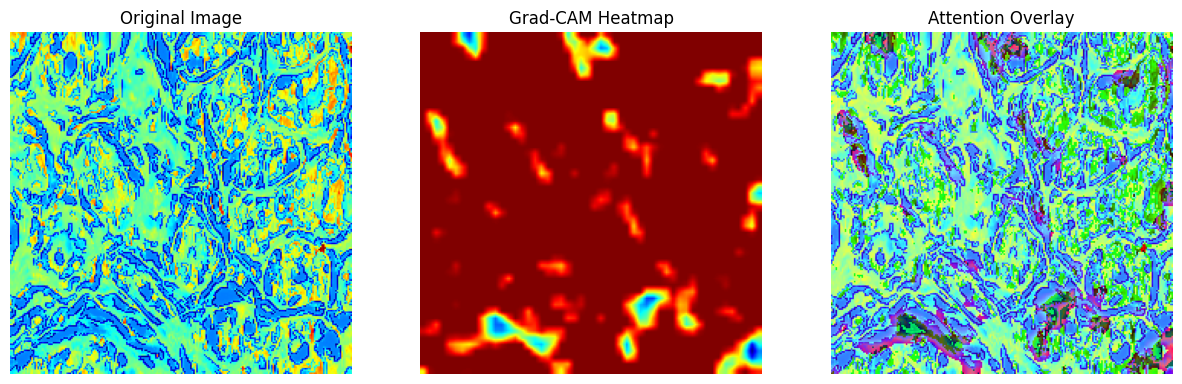


Stage 8 Completed Successfully
Models Saved + Grad-CAM Generated


In [26]:
# =========================================================
# STAGE 8 — EXPLAINABLE AI (GRAD-CAM VISUALIZATION)
# =========================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2


# =========================================================
# FUNCTION TO GENERATE GRAD-CAM
# =========================================================

def generate_gradcam(model, image, last_conv_layer_name):

    grad_model = tf.keras.models.Model(
        [model.inputs],
        [
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(image)

        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0)

    heatmap /= tf.reduce_max(heatmap)

    return heatmap.numpy()


# =========================================================
# SELECT SAMPLE IMAGE
# =========================================================

sample_image, sample_label = next(iter(val_dataset))

sample = sample_image[0]

input_image = tf.expand_dims(
    sample,
    axis=0
)


# =========================================================
# FIND LAST CONV LAYER
# =========================================================

last_conv_layer = None

for layer in reversed(histopathology_expert.layers):

    if isinstance(layer, tf.keras.layers.Conv2D):

        last_conv_layer = layer.name

        break


print("Last Conv Layer:", last_conv_layer)


# =========================================================
# GENERATE HEATMAP
# =========================================================

heatmap = generate_gradcam(
    histopathology_expert,
    input_image,
    last_conv_layer
)


# =========================================================
# PREPARE VISUALIZATION
# =========================================================

original_image = sample.numpy()

heatmap = cv2.resize(
    heatmap,
    (IMG_SIZE, IMG_SIZE)
)

heatmap = np.uint8(
    255 * heatmap
)

heatmap = cv2.applyColorMap(
    heatmap,
    cv2.COLORMAP_JET
)

superimposed_img = (
    heatmap * 0.4 +
    original_image * 255
)

superimposed_img = np.uint8(
    superimposed_img
)


# =========================================================
# DISPLAY RESULTS
# =========================================================

plt.figure(figsize=(15, 5))


# Original Image
plt.subplot(1, 3, 1)

plt.imshow(original_image)

plt.title("Original Image")

plt.axis("off")


# Heatmap
plt.subplot(1, 3, 2)

plt.imshow(heatmap)

plt.title("Grad-CAM Heatmap")

plt.axis("off")


# Overlay
plt.subplot(1, 3, 3)

plt.imshow(superimposed_img)

plt.title("Attention Overlay")

plt.axis("off")


plt.show()


# =========================================================
# SAVE MODELS
# =========================================================

histopathology_expert.save(
    "histopathology_model.keras"
)

ultrasound_expert.save(
    "ultrasound_model.keras"
)

xray_expert.save(
    "xray_model.keras"
)


print("\n===================================")
print("Stage 8 Completed Successfully")
print("Models Saved + Grad-CAM Generated")
print("===================================")

In [27]:
# =========================================================
# STAGE 9 — MULTIMODAL FUSION MODEL
# =========================================================

import tensorflow as tf
import numpy as np

from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras import Input


# =========================================================
# FEATURE EXTRACTORS
# Remove Final Classification Layers
# =========================================================

histopathology_feature_extractor = Model(
    inputs=histopathology_expert.input,
    outputs=histopathology_expert.layers[-2].output
)

ultrasound_feature_extractor = Model(
    inputs=ultrasound_expert.input,
    outputs=ultrasound_expert.layers[-2].output
)

xray_feature_extractor = Model(
    inputs=xray_expert.input,
    outputs=xray_expert.layers[-2].output
)


# Freeze expert models
histopathology_feature_extractor.trainable = False
ultrasound_feature_extractor.trainable = False
xray_feature_extractor.trainable = False


# =========================================================
# MULTIMODAL INPUTS
# =========================================================

histopathology_input = Input(
    shape=(224, 224, 3),
    name="histopathology_input"
)

ultrasound_input = Input(
    shape=(224, 224, 3),
    name="ultrasound_input"
)

xray_input = Input(
    shape=(224, 224, 3),
    name="xray_input"
)


# =========================================================
# FEATURE EXTRACTION
# =========================================================

histopathology_features = (
    histopathology_feature_extractor(
        histopathology_input
    )
)

ultrasound_features = (
    ultrasound_feature_extractor(
        ultrasound_input
    )
)

xray_features = (
    xray_feature_extractor(
        xray_input
    )
)


# =========================================================
# FEATURE FUSION
# =========================================================

fusion = Concatenate(name="fusion_layer")([
    histopathology_features,
    ultrasound_features,
    xray_features
])


# =========================================================
# FUSION NETWORK
# =========================================================

x = Dense(
    256,
    activation="relu"
)(fusion)

x = BatchNormalization()(x)

x = Dropout(0.4)(x)


x = Dense(
    128,
    activation="relu"
)(x)

x = BatchNormalization()(x)

x = Dropout(0.3)(x)


# =========================================================
# ATTENTION MECHANISM
# =========================================================

attention = Dense(
    128,
    activation="sigmoid"
)(x)

x = Multiply()([
    x,
    attention
])


# =========================================================
# FINAL CLASSIFICATION
# =========================================================

output = Dense(
    1,
    activation="sigmoid",
    name="multimodal_output"
)(x)


# =========================================================
# MULTIMODAL MODEL
# =========================================================

multimodal_model = Model(
    inputs=[
        histopathology_input,
        ultrasound_input,
        xray_input
    ],

    outputs=output
)


# =========================================================
# MODEL SUMMARY
# =========================================================

print("\n===================================")
print("MULTIMODAL FUSION MODEL")
print("===================================\n")

multimodal_model.summary()


# =========================================================
# COMPILE MODEL
# =========================================================

multimodal_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)


print("\n===================================")
print("Stage 9 Completed Successfully")
print("Multimodal Fusion Model Created")
print("===================================")


MULTIMODAL FUSION MODEL



Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ histopathology_inp… │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ultrasound_input    │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ xray_input          │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_4        │ (None, 128)       │    109,760 │ histopathology_i… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_5        │ (None, 128)       │    110,656 │ ultrasound_input… │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_6        │ (None, 128)       │    110,656 │ xray_input[0][0]  │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_layer        │ (None, 384)       │          0 │ functional_4[0][… │
│ (Concatenate)       │                   │            │ functional_5[0][… │
│                     │                   │            │ functional_6[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 256)       │     98,560 │ fusion_layer[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_6[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 128)       │     32,896 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_7[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 128)       │     16,512 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 128)       │          0 │ dropout_4[0][0],  │
│                     │                   │            │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multimodal_output   │ (None, 1)         │        129 │ multiply[0][0]    │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 480,705 (1.83 MB)

 Trainable params: 148,865 (581.50 KB)

 Non-trainable params: 331,840 (1.27 MB)


Stage 9 Completed Successfully
Multimodal Fusion Model Created


In [28]:
# =========================================================
# STAGE 10 UPDATED
# HISTOPATHOLOGY + ULTRASOUND FUSION MODEL
# =========================================================

import tensorflow as tf
import numpy as np


# =========================================================
# FEATURE EXTRACTORS
# =========================================================

histopathology_feature_extractor = tf.keras.models.Model(
    inputs=histopathology_expert.input,
    outputs=histopathology_expert.layers[-2].output
)

ultrasound_feature_extractor = tf.keras.models.Model(
    inputs=ultrasound_expert.input,
    outputs=ultrasound_expert.layers[-2].output
)


histopathology_feature_extractor.trainable = False
ultrasound_feature_extractor.trainable = False


# =========================================================
# MULTIMODAL INPUTS
# =========================================================

histopathology_input = tf.keras.Input(
    shape=(224, 224, 3),
    name="histopathology_input"
)

ultrasound_input = tf.keras.Input(
    shape=(224, 224, 3),
    name="ultrasound_input"
)


# =========================================================
# FEATURE EXTRACTION
# =========================================================

hist_features = (
    histopathology_feature_extractor(
        histopathology_input
    )
)

ultra_features = (
    ultrasound_feature_extractor(
        ultrasound_input
    )
)


# =========================================================
# FEATURE FUSION
# =========================================================

fusion = tf.keras.layers.Concatenate()([
    hist_features,
    ultra_features
])


# =========================================================
# FUSION NETWORK
# =========================================================

x = tf.keras.layers.Dense(
    128,
    activation="relu"
)(fusion)

x = tf.keras.layers.BatchNormalization()(x)

x = tf.keras.layers.Dropout(0.4)(x)


x = tf.keras.layers.Dense(
    64,
    activation="relu"
)(x)

x = tf.keras.layers.Dropout(0.3)(x)


# =========================================================
# FINAL OUTPUT
# =========================================================

fusion_output = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)


# =========================================================
# FINAL FUSION MODEL
# =========================================================

fusion_model = tf.keras.Model(
    inputs=[
        histopathology_input,
        ultrasound_input
    ],

    outputs=fusion_output
)


# =========================================================
# COMPILE MODEL
# =========================================================

fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)


# =========================================================
# CREATE FUSION DATASET
# =========================================================

min_samples = min(
    len(histopathology_train),
    len(ultrasound_train)
)


hist_paths = (
    histopathology_train["Path"]
    .values[:min_samples]
)

ultra_paths = (
    ultrasound_train["Path"]
    .values[:min_samples]
)

fusion_labels = (
    histopathology_train["Label"]
    .values[:min_samples]
    .astype(np.float32)
)


# =========================================================
# IMAGE PREPROCESSING
# =========================================================

IMG_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 40


def load_image(path):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    return image


def fusion_preprocess(
    hist_path,
    ultra_path,
    label
):

    hist_image = load_image(hist_path)

    ultra_image = load_image(ultra_path)

    return (
        {
            "histopathology_input": hist_image,
            "ultrasound_input": ultra_image
        },
        label
    )


# =========================================================
# TF DATASET
# =========================================================

fusion_dataset = tf.data.Dataset.from_tensor_slices(
    (
        hist_paths,
        ultra_paths,
        fusion_labels
    )
)

fusion_dataset = (
    fusion_dataset
    .shuffle(1000)
    .map(fusion_preprocess)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


# =========================================================
# TRAIN / VALIDATION SPLIT
# =========================================================

dataset_size = min_samples

train_size = int(
    0.8 * dataset_size
)

train_dataset_fusion = fusion_dataset.take(
    train_size // BATCH_SIZE
)

val_dataset_fusion = fusion_dataset.skip(
    train_size // BATCH_SIZE
)


# =========================================================
# CALLBACKS
# =========================================================

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=3,
    min_lr=1e-6
)


# =========================================================
# TRAIN FUSION MODEL
# =========================================================

print("\n===================================")
print("TRAINING HISTOPATHOLOGY + ULTRASOUND")
print("MULTIMODAL FUSION MODEL")
print("===================================\n")


fusion_history = fusion_model.fit(
    train_dataset_fusion,
    validation_data=val_dataset_fusion,
    epochs=EPOCHS,
    callbacks=[
        early_stop,
        reduce_lr
    ]
)


# =========================================================
# SAVE MODEL
# =========================================================

fusion_model.save(
    "hist_ultrasound_fusion_model.keras"
)


print("\n===================================")
print("Fusion Training Completed")
print("Model Saved Successfully")
print("===================================")


TRAINING HISTOPATHOLOGY + ULTRASOUND
MULTIMODAL FUSION MODEL

Epoch 1/40
28/28 ━━━━━━━━━━━━━━━━━━━━ 11s 168ms/step - accuracy: 0.5335 - auc: 0.4893 - loss: 1.0046 - precision: 0.5274 - recall: 0.6844 - val_accuracy: 0.4655 - val_auc: 0.5650 - val_loss: 0.7204 - val_precision: 0.4314 - val_recall: 0.9167 - learning_rate: 1.0000e-04
Epoch 2/40
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.4554 - auc: 0.4726 - loss: 1.0444 - precision: 0.4505 - recall: 0.5668 - val_accuracy: 0.5690 - val_auc: 0.5963 - val_loss: 0.6839 - val_precision: 0.5510 - val_recall: 0.9000 - learning_rate: 1.0000e-04
Epoch 3/40
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.5223 - auc: 0.5533 - loss: 0.9104 - precision: 0.5123 - recall: 0.6606 - val_accuracy: 0.5603 - val_auc: 0.6378 - val_loss: 0.6747 - val_precision: 0.5412 - val_recall: 0.7931 - learning_rate: 1.0000e-04
Epoch 4/40
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.5536 - auc: 0.5636 - loss: 0.8674 - precision: 0.5418 - recall:

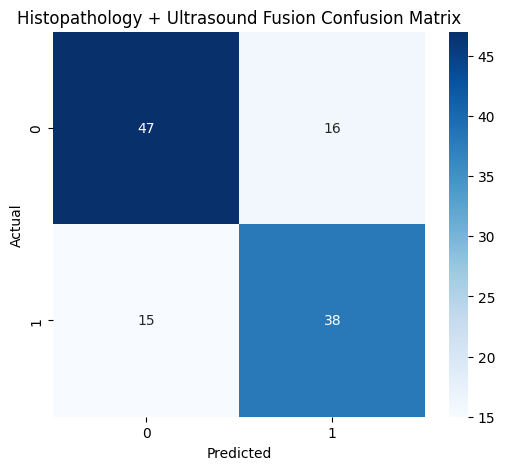

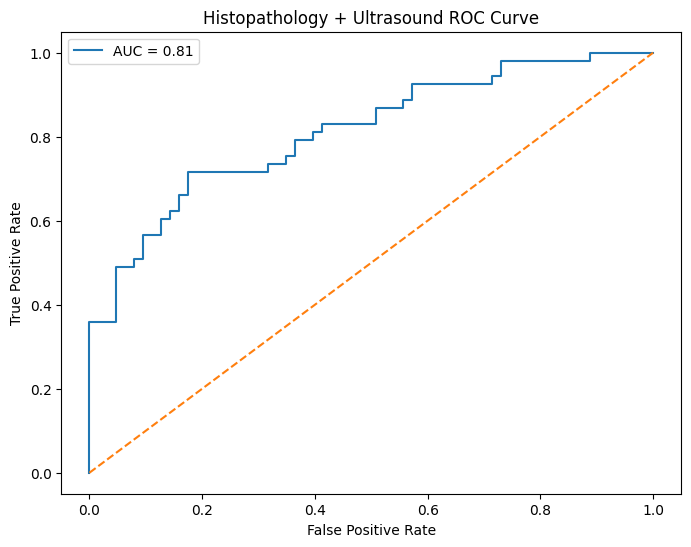

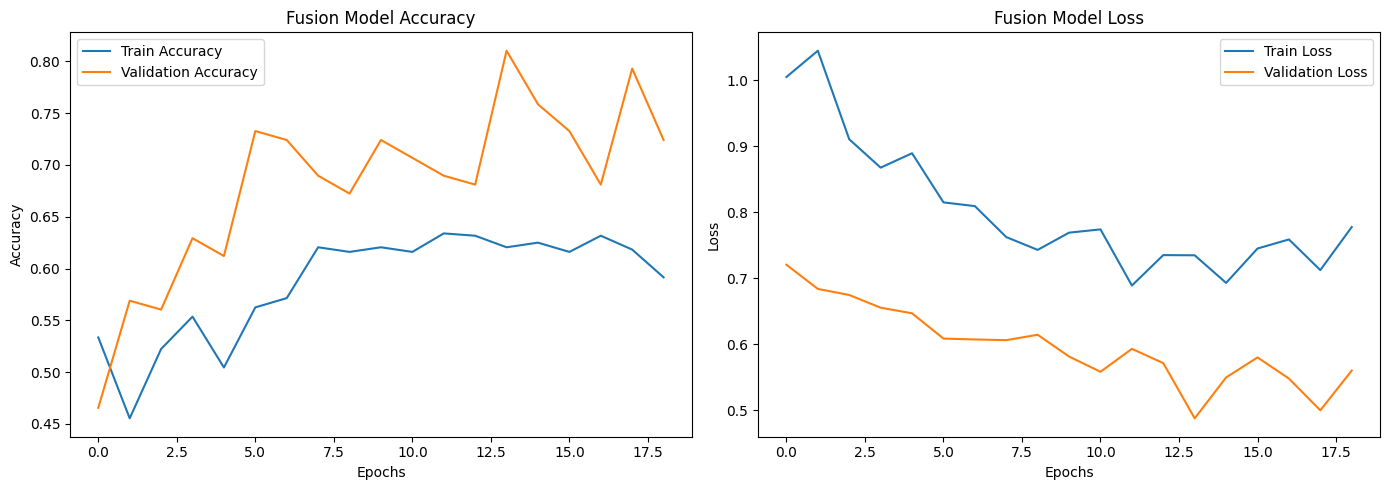


FINAL FUSION CLASSIFICATION REPORT

              precision    recall  f1-score   support

           0       0.76      0.75      0.75        63
           1       0.70      0.72      0.71        53

    accuracy                           0.73       116
   macro avg       0.73      0.73      0.73       116
weighted avg       0.73      0.73      0.73       116


FINAL FUSION RESULTS

Fusion Accuracy : 0.7328
Fusion AUC      : 0.8128

Final Fusion Model Saved Successfully

MULTIMODAL BREAST CANCER PROJECT
COMPLETED SUCCESSFULLY


In [33]:
# =========================================================
# FINAL EVALUATION
# HISTOPATHOLOGY + ULTRASOUND FUSION MODEL
# =========================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

# Collect predictions and labels from the validation dataset
# in the same pass, so they stay aligned.
all_true_labels = []
all_predictions = []

for batch_inputs, batch_labels in val_dataset_fusion:
    batch_predictions = fusion_model(
        batch_inputs,
        training=False
    ).numpy()

    all_true_labels.append(batch_labels.numpy().reshape(-1))
    all_predictions.append(batch_predictions.reshape(-1))

fusion_true_labels = np.concatenate(all_true_labels).astype(int)
fusion_predictions = np.concatenate(all_predictions)

fusion_pred_labels = (fusion_predictions >= 0.5).astype(int)

# Confusion matrix
fusion_cm = confusion_matrix(
    fusion_true_labels,
    fusion_pred_labels
)

plt.figure(figsize=(6, 5))
sns.heatmap(fusion_cm, annot=True, fmt="d", cmap="Blues")
plt.title("Histopathology + Ultrasound Fusion Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# ROC curve and AUC require both classes in the validation labels.
if len(np.unique(fusion_true_labels)) == 2:
    fusion_fpr, fusion_tpr, _ = roc_curve(
        fusion_true_labels,
        fusion_predictions
    )
    fusion_auc = auc(fusion_fpr, fusion_tpr)

    plt.figure(figsize=(8, 6))
    plt.plot(fusion_fpr, fusion_tpr, label=f"AUC = {fusion_auc:.2f}")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.title("Histopathology + Ultrasound ROC Curve")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.show()
else:
    fusion_auc = float("nan")
    print("AUC and ROC curve were skipped: validation labels contain only one class.")

# Training curves
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(fusion_history.history["accuracy"], label="Train Accuracy")
plt.plot(fusion_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Fusion Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(fusion_history.history["loss"], label="Train Loss")
plt.plot(fusion_history.history["val_loss"], label="Validation Loss")
plt.title("Fusion Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# Classification report and metrics
print("\n===================================")
print("FINAL FUSION CLASSIFICATION REPORT")
print("===================================\n")
print(classification_report(fusion_true_labels, fusion_pred_labels))

fusion_accuracy = np.mean(fusion_true_labels == fusion_pred_labels)

print("\n===================================")
print("FINAL FUSION RESULTS")
print("===================================\n")
print(f"Fusion Accuracy : {fusion_accuracy:.4f}")
print(f"Fusion AUC      : {fusion_auc:.4f}")

# Save the model created and trained above
fusion_model.save("best_hist_ultrasound_fusion_model.keras")
print("\nFinal Fusion Model Saved Successfully")

print("\n===================================")
print("MULTIMODAL BREAST CANCER PROJECT")
print("COMPLETED SUCCESSFULLY")
print("===================================")